# Quantify the position effect

This notebook measures how large the position effect is on the validation plates and how much of it the correction removes, with five measurements.
It changes no data: it reads the well medians that `1.fit_position_correction.ipynb` cached and the committed fit.

The DMSO wells are the backbone of the measurements, because they sit at the same positions on all five plates: 18 healthy and 18 failing positions, in blocks of columns that cover all six rows (failing in columns 2, 4, and 10, healthy in 3, 9, and 11).
The variation of a DMSO position between the plates is noise, and the variation between the positions of one cell type is position.
The compound wells sit on one plate each (three compounds per plate), so they cannot be replicated.

1. **Position variation of every feature.** The share of the variation within each cell type of DMSO that is position, with the chance level subtracted (`vpu.position_variance_share`), on the uncorrected wells, after a tilt fit on all plates (in-sample, which a fit on its own data always favors), and after a tilt fit on the other four plates (held-out, `vpu.leave_one_plate_out_correction`).
2. **Position against biology.** The size of the healthy against failing DMSO difference on each plate, with and without the correction, next to the difference that the tilt predicts between the healthy and the failing positions.
3. **Does the row effect carry over between cell types?** The correction assumes position moves healthy and failing cells equally. The failing DMSO sits in columns 2, 4, and 10 and the healthy DMSO in columns 3, 9, and 11, so a tilt fit on one cell type has no column effect for the other and can only be tested on the rows. We fit the tilt on the failing DMSO only and check whether its row effects predict the row pattern of the healthy DMSO, and the other way round. This layout cannot test whether the column effects carry over.
4. **Per plate.** The distance of every DMSO well from the mean of its cell type, on the layout of each plate, before and after the held-out correction.
5. **How well the tilt terms are determined.** The size of each row and column term of the tilt, with its uncertainty from leaving each plate out in turn.

Effect sizes are the length of a difference of profiles over all features, in standard deviations of a single cell.

**Output**

- `figures/quantify/`: one figure for each measurement. The tables behind them are printed in the notebook.

## Import libraries

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../../../utils")
import position_correction_utils as pcu
import validation_position_utils as vpu

## Set paths and parameters

In [2]:
figure_dir = pathlib.Path("figures") / "quantify"
figure_dir.mkdir(parents=True, exist_ok=True)

fit_path = pathlib.Path("position_correction_fit.npz")
well_medians_cache = pathlib.Path("well_medians.parquet")
for path in (fit_path, well_medians_cache):
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run 1.fit_position_correction.ipynb first.")

min_cells = 50  # minimum cells for a well to be used (as in the screen)
HEALTHY, FAILING = vpu.HEALTHY_CELL_TYPE, vpu.FAILING_CELL_TYPE
colors = {"raw": "#d62728", "in_sample": "#7f7f7f", "held_out": "#1f77b4"}

## Load the fit and the well medians

In [3]:
fit = pcu.load_fit(fit_path)
well_medians, features = vpu.load_or_build_well_medians(
    well_medians_cache, ".", platemap_dir="../../metadata/platemaps"
)
features = [feature for feature in fit["features"] if feature in well_medians.columns]
feature_index = [list(fit["features"]).index(feature) for feature in features]
coef, center = fit["coef"][:, feature_index], fit["center"][feature_index]

wells = well_medians[well_medians["n"] >= min_cells].reset_index(drop=True)
rows, cols0 = pcu.well_index(wells["well"])
wells["row"], wells["column"] = rows, wells["well"].str[1:].astype(int)
raw = wells[features].to_numpy(float)
# the shift that the tilt predicts at every well (the correction subtracts it)
tilt_at_wells = pcu.tilt(coef, center, rows, cols0)
corrected = raw - tilt_at_wells
is_dmso = (wells["treatment"] == "DMSO").to_numpy()
is_healthy = (is_dmso & (wells["cell_type"] == HEALTHY)).to_numpy()
is_failing = (is_dmso & (wells["cell_type"] == FAILING)).to_numpy()
print("Wells:", len(wells), "| Features:", len(features), "| Plates:", wells["plate"].nunique())

Wells: 300 | Features: 2453 | Plates: 5


## 1. Position variation of every feature

For each feature, the share of the variation within the two DMSO groups that is position.
Zero is the chance level: no more variation between positions than the noise between plates predicts.

In [4]:
shares = vpu.held_out_position_variance(well_medians, features, min_cells)
shares = pd.concat(
    [shares, pd.DataFrame([vpu.parse_feature_family(name) for name in shares["feature"]])],
    axis=1,
)
valid = shares.dropna(subset=["raw", "in_sample", "held_out"])

has_effect = valid["raw"] > 0.2
removed = 1 - valid.loc[has_effect, "held_out_excess"] / valid.loc[has_effect, "raw_excess"]
excess_left = {
    column: valid[f"{column}_excess"].sum() / valid["raw_excess"].sum()
    for column in ("raw", "in_sample", "held_out")
}
summary = pd.DataFrame(
    {
        "stage": ["raw", "in-sample correction", "held-out correction"],
        "median_share": [valid[c].median() for c in ("raw", "in_sample", "held_out")],
        "p90_share": [valid[c].quantile(0.9) for c in ("raw", "in_sample", "held_out")],
        "features_above_0.2": [(valid[c] > 0.2).mean() for c in ("raw", "in_sample", "held_out")],
        "position_variation_left": [excess_left[c] for c in ("raw", "in_sample", "held_out")],
    }
)
summary["features"] = len(valid)
print(summary.round(3).to_string(index=False))
print(
    f"\nFeatures with a clear position effect (share above 0.2): {int(has_effect.sum())}. "
    f"The held-out correction removes a median of {removed.median():.2f} of their position variation "
    f"(quartiles {removed.quantile(0.25):.2f} to {removed.quantile(0.75):.2f}); "
    f"{(removed < 0).mean():.0%} of these features get worse."
)

               stage  median_share  p90_share  features_above_0.2  position_variation_left  features
                 raw         0.257      0.743               0.553                    1.000      2415
in-sample correction         0.098      0.407               0.358                    0.139      2415
 held-out correction         0.052      0.336               0.283                    0.083      2415

Features with a clear position effect (share above 0.2): 1335. The held-out correction removes a median of 0.85 of their position variation (quartiles 0.67 to 0.92); 6% of these features get worse.


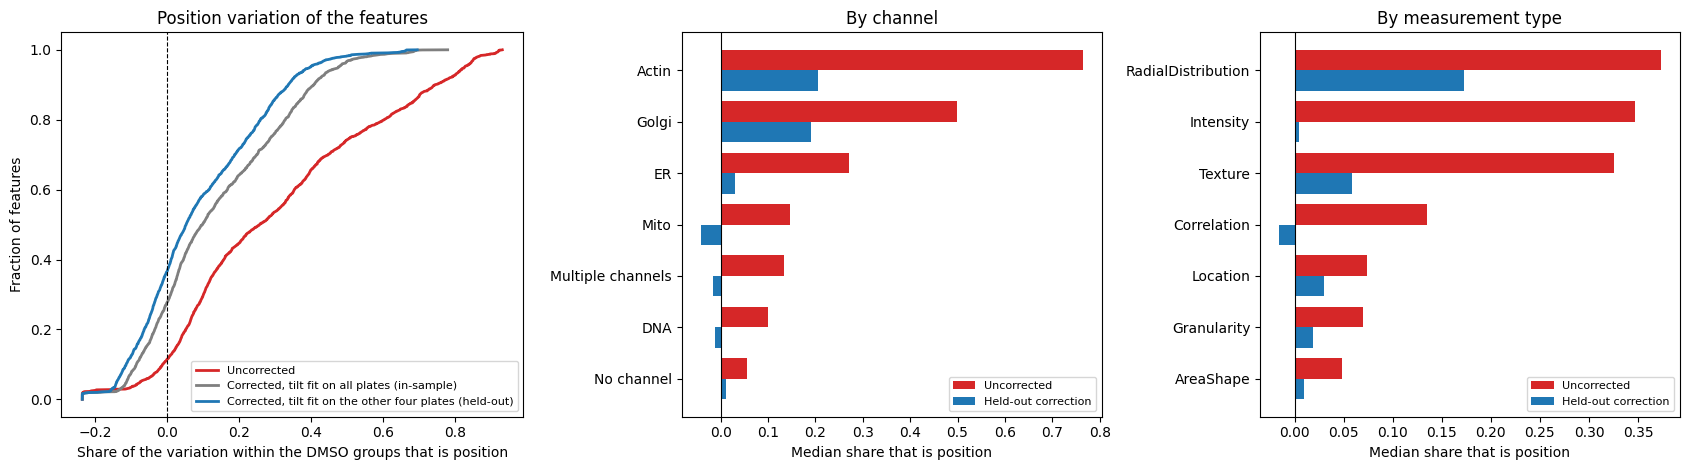

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.1, 1, 1]})
labels = {"raw": "Uncorrected", "in_sample": "Corrected, tilt fit on all plates (in-sample)", "held_out": "Corrected, tilt fit on the other four plates (held-out)"}
ax = axes[0]
for column in ("raw", "in_sample", "held_out"):
    values = np.sort(valid[column].to_numpy())
    ax.plot(values, np.arange(1, len(values) + 1) / len(values), color=colors[column], label=labels[column], lw=2)
ax.axvline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("Share of the variation within the DMSO groups that is position")
ax.set_ylabel("Fraction of features")
ax.set_title("Position variation of the features")
ax.legend(fontsize=8, loc="lower right")
for ax, family, title in ((axes[1], "channel", "By channel"), (axes[2], "measurement", "By measurement type")):
    medians = valid.groupby(family)[["raw", "held_out"]].median()
    medians = medians[valid.groupby(family).size() >= 20].sort_values("raw")
    y = np.arange(len(medians))
    ax.barh(y + 0.2, medians["raw"], height=0.4, color=colors["raw"], label="Uncorrected")
    ax.barh(y - 0.2, medians["held_out"], height=0.4, color=colors["held_out"], label="Held-out correction")
    ax.set_yticks(y)
    ax.set_yticklabels(medians.index)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Median share that is position")
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figure_dir / "position_variance_by_feature.png", dpi=150)
plt.show()

## 2. Position against biology

The healthy against failing DMSO difference on each plate (the length of the difference of the mean profiles of the two cell types), before and after the correction.
The line is the difference that the tilt predicts between the positions of the healthy and the failing wells.
If position were all of the difference, the corrected difference would be zero.

In [6]:
records = []
for plate in sorted(wells["plate"].unique()):
    in_plate = (wells["plate"] == plate).to_numpy()
    h, f = in_plate & is_healthy, in_plate & is_failing
    records.append(
        {
            "plate": plate,
            "raw": np.linalg.norm(raw[h].mean(0) - raw[f].mean(0)),
            "corrected": np.linalg.norm(corrected[h].mean(0) - corrected[f].mean(0)),
        }
    )
position_vs_biology = pd.DataFrame(records)
position_vs_biology["share_kept"] = position_vs_biology["corrected"] / position_vs_biology["raw"]
tilt_healthy_vs_failing = float(np.linalg.norm(tilt_at_wells[is_healthy].mean(0) - tilt_at_wells[is_failing].mean(0)))
position_vs_biology["tilt_healthy_vs_failing"] = tilt_healthy_vs_failing
print(position_vs_biology.round(2).to_string(index=False))

# the same difference for the profiles averaged over the five plates (less noise than a single plate)
pooled_raw = np.linalg.norm(raw[is_healthy].mean(0) - raw[is_failing].mean(0))
pooled_corrected = np.linalg.norm(corrected[is_healthy].mean(0) - corrected[is_failing].mean(0))
print(f"Plate-averaged healthy minus failing difference: {pooled_raw:.1f} before and {pooled_corrected:.1f} after the correction")

                       plate   raw  corrected  share_kept  tilt_healthy_vs_failing
CARD-CelIns-CX7_261030160001 12.92      12.92         1.0                      0.0
CARD-CelIns-CX7_261031160001 14.55      14.55         1.0                      0.0
CARD-CelIns-CX7_261101160003 12.82      12.82         1.0                      0.0
CARD-CelIns-CX7_261102080001 13.76      13.76         1.0                      0.0
CARD-CelIns-CX7_261102150001 12.97      12.97         1.0                      0.0
Plate-averaged healthy minus failing difference: 13.0 before and 13.0 after the correction


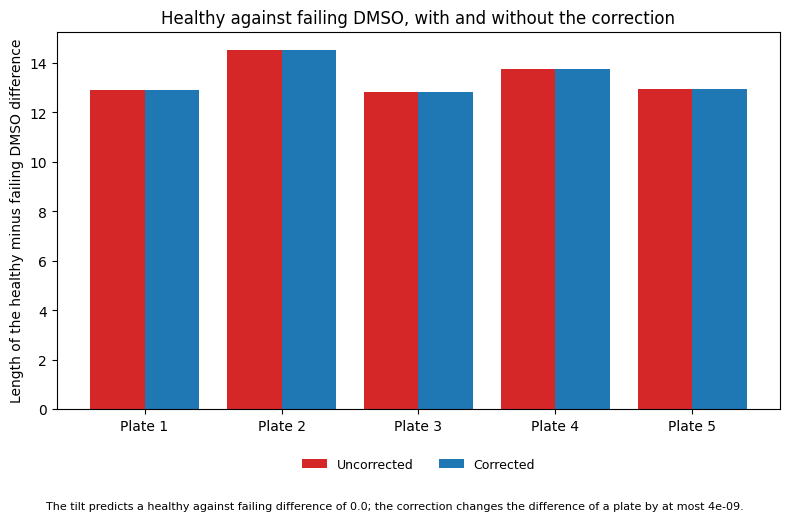

In [7]:
largest_change = (position_vs_biology["raw"] - position_vs_biology["corrected"]).abs().max()
fig, ax = plt.subplots(figsize=(8, 5.2))
x = np.arange(len(position_vs_biology))
ax.bar(x - 0.2, position_vs_biology["raw"], 0.4, color=colors["raw"], label="Uncorrected")
ax.bar(x + 0.2, position_vs_biology["corrected"], 0.4, color=colors["held_out"], label="Corrected")
ax.set_xticks(x)
ax.set_xticklabels([f"Plate {i + 1}" for i in x])
ax.set_ylabel("Length of the healthy minus failing DMSO difference")
ax.set_title("Healthy against failing DMSO, with and without the correction")
# the tilt has no healthy-against-failing component, so the two bars of a plate are the same
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9, frameon=False)
fig.text(
    0.5,
    0.01,
    f"The tilt predicts a healthy against failing difference of {tilt_healthy_vs_failing:.1f}; the correction changes the difference of a plate by at most {largest_change:.0e}.",
    ha="center",
    fontsize=8,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(figure_dir / "position_vs_biology.png", dpi=150)
plt.show()

## 3. Does the row effect carry over between cell types?

The correction subtracts one tilt from healthy and failing cells.
That is right only if position moves both cell types in the same way.
The failing DMSO is in columns 2, 4, and 10 and the healthy DMSO in columns 3, 9, and 11, so a tilt fit on the wells of one cell type has no observation for the columns of the other.
The ridge sets those column effects to zero, and what the fit predicts for the other cell type varies only by row.
We therefore compare the row patterns: the tilt fit on one cell type predicts the effect of each of the six rows, and we compare it with the mean profile of each row in the other cell type.
**This layout cannot test whether the column effects carry over between cell types.**

For each direction we report the cosine between the predicted and the observed row pattern (1 is a perfect match), the slope of the observed on the predicted pattern (1 means the right size), and a noise reference: the cosine between the row patterns of two halves of the plates (plates 1, 3, 5 against plates 2, 4).
The reference shows how well two independent measurements of the same cell type agree, and it is not an upper bound for the cosine of the prediction.

In [8]:
dmso = wells[is_dmso]


plate_order = sorted(wells["plate"].unique())
records = []
for source, target in ((FAILING, HEALTHY), (HEALTHY, FAILING)):
    source_wells = dmso[dmso["cell_type"] == source]
    tilt_fit = vpu.fit_compound_adjusted_tilt(source_wells, features, min_cells, include_controls=True)
    target_wells = dmso[dmso["cell_type"] == target]
    row_labels, observed = vpu.mean_row_pattern(target_wells, features)
    predicted = vpu.tilt_row_pattern(tilt_fit)
    cosine, slope = vpu.cosine_and_slope(observed, predicted)
    # noise reference: the row patterns of two halves of the plates
    half_a = target_wells[target_wells["plate"].isin(plate_order[0::2])]
    half_b = target_wells[target_wells["plate"].isin(plate_order[1::2])]
    agreement, _ = vpu.cosine_and_slope(vpu.mean_row_pattern(half_a, features)[1], vpu.mean_row_pattern(half_b, features)[1])
    records.append({"fit_on": source, "predicts": target, "cosine": cosine, "slope": slope, "half_agreement_cosine": agreement, "n_rows": len(row_labels)})
cross = pd.DataFrame(records)
print(cross.round(2).to_string(index=False))

    fit_on   predicts  cosine  slope  half_agreement_cosine  n_rows
   failing nonfailing    0.92   1.09                   0.90       6
nonfailing    failing    0.92   0.78                   0.92       6


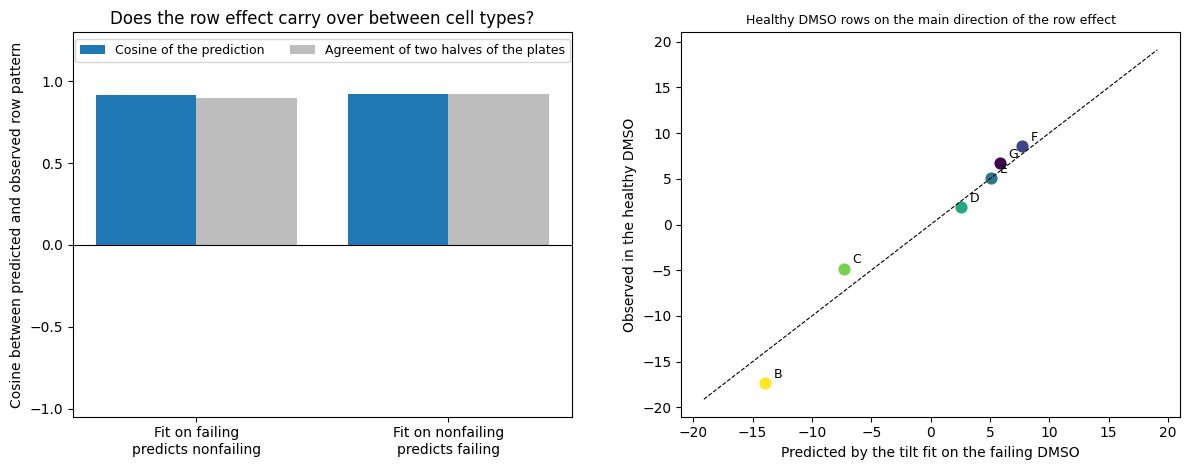

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
x = np.arange(len(cross))
ax.bar(x - 0.2, cross["cosine"], 0.4, color=colors["held_out"], label="Cosine of the prediction")
ax.bar(x + 0.2, cross["half_agreement_cosine"], 0.4, color="#bdbdbd", label="Agreement of two halves of the plates")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"Fit on {a}\npredicts {b}" for a, b in zip(cross["fit_on"], cross["predicts"])])
ax.set_ylim(-1.05, 1.3)
ax.set_ylabel("Cosine between predicted and observed row pattern")
ax.set_title("Does the row effect carry over between cell types?")
ax.legend(fontsize=9, loc="upper center", ncol=2)
ax = axes[1]
tilt_fit = vpu.fit_compound_adjusted_tilt(dmso[dmso["cell_type"] == FAILING], features, min_cells, include_controls=True)
row_labels, observed = vpu.mean_row_pattern(dmso[dmso["cell_type"] == HEALTHY], features)
predicted = vpu.tilt_row_pattern(tilt_fit)
direction = np.linalg.svd(predicted, full_matrices=False)[2][0]
row_colors = dict(zip(pcu.ROWS, plt.get_cmap("viridis")(np.linspace(1, 0, pcu.N_ROW_TERMS))))
for row, px, py in zip(row_labels, predicted @ direction, observed @ direction):
    ax.scatter(px, py, color=row_colors[row], s=60)
    ax.annotate(row, (px, py), textcoords="offset points", xytext=(6, 4), fontsize=9)
limit = max(abs(predicted @ direction).max(), abs(observed @ direction).max()) * 1.1
ax.plot([-limit, limit], [-limit, limit], color="black", lw=0.8, ls="--")
ax.set_xlabel("Predicted by the tilt fit on the failing DMSO")
ax.set_ylabel("Observed in the healthy DMSO")
ax.set_title("Healthy DMSO rows on the main direction of the row effect")
ax.title.set_size(9)
fig.tight_layout()
fig.savefig(figure_dir / "row_effect_cross_cell_type.png", dpi=150)
plt.show()

## 4. Per plate: distance of every DMSO well from its cell type

For every DMSO well, the distance between its profile and the mean profile of its cell type over all positions and plates.
Position moves the wells of a cell type apart, so before the correction the wells at the edges of the plate sit far from the mean.
After the held-out correction (the tilt is fit on the other four plates), what is left is noise and whatever the correction misses.
The compound wells are not part of this measurement and are shown in grey.

In [10]:
held_out_profiles = vpu.leave_one_plate_out_correction(wells, features, min_cells)


deviation = wells[["plate", "well", "treatment", "cell_type"]].copy()
deviation["row"] = deviation["well"].str[0]
deviation["column"] = deviation["well"].str[1:].astype(int)
deviation["raw"] = vpu.distance_from_class_mean(raw, is_healthy, is_failing)
deviation["held_out"] = vpu.distance_from_class_mean(held_out_profiles, is_healthy, is_failing)
deviation = deviation[is_dmso]

by_row = deviation.groupby("row")[["raw", "held_out"]].mean()
by_row["share_kept"] = by_row["held_out"] / by_row["raw"]
print("Mean distance from the mean of the cell type, by plate row")
print(by_row.round(2).to_string())

Mean distance from the mean of the cell type, by plate row
       raw  held_out  share_kept
row                             
B    19.39     12.62        0.65
C    11.30     10.66        0.94
D     9.82      9.35        0.95
E    10.02      9.23        0.92
F    11.96      9.63        0.81
G    11.66     11.21        0.96


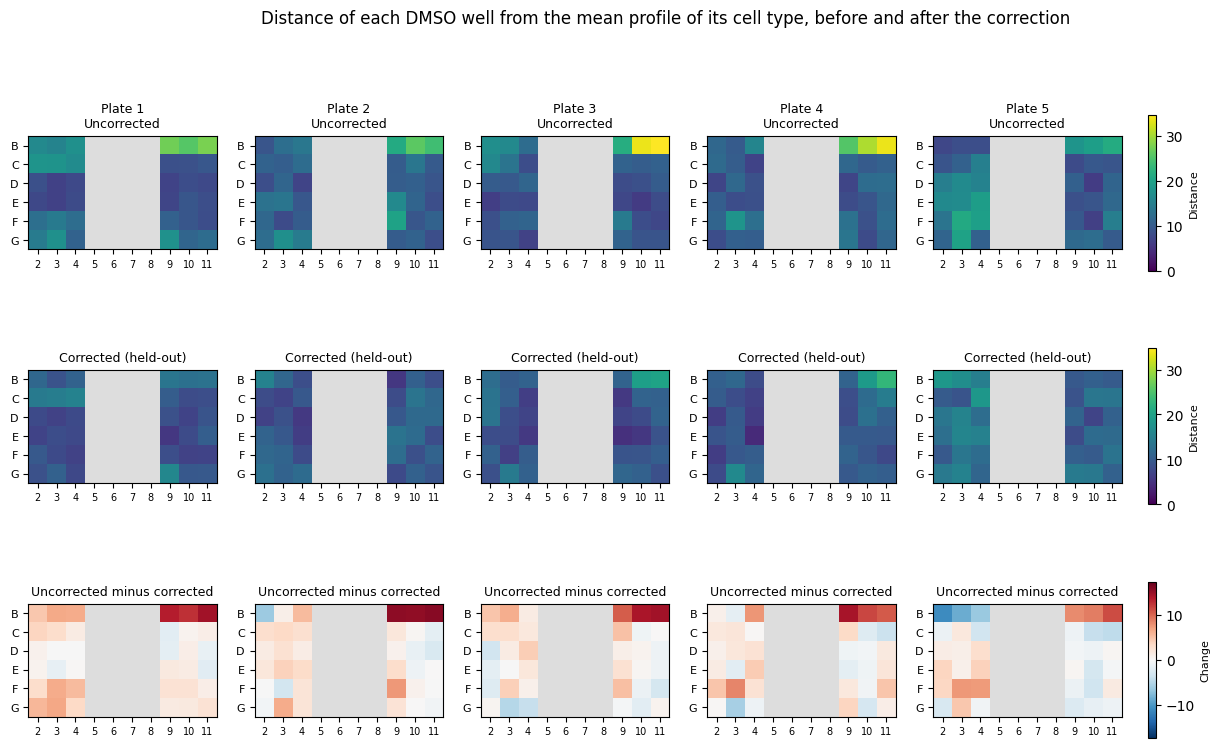

In [11]:
plates = sorted(deviation["plate"].unique())
rows_label = list(pcu.ROWS)
column_numbers = list(range(2, 12))


vmax = max(deviation["raw"].max(), deviation["held_out"].max())
fig, axes = plt.subplots(3, len(plates), figsize=(3.4 * len(plates), 8.6), squeeze=False)
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("#dddddd")
diverging = plt.get_cmap("RdBu_r").copy()
diverging.set_bad("#dddddd")
for j, plate in enumerate(plates):
    raw_grid = vpu.plate_layout_grid(deviation, plate, "raw", rows_label, column_numbers)
    held_grid = vpu.plate_layout_grid(deviation, plate, "held_out", rows_label, column_numbers)
    panels = [
        (raw_grid, cmap, 0, vmax, "Uncorrected"),
        (held_grid, cmap, 0, vmax, "Corrected (held-out)"),
        (raw_grid - held_grid, diverging, -vmax / 2, vmax / 2, "Uncorrected minus corrected"),
    ]
    for i, (grid, colormap, low, high, title) in enumerate(panels):
        ax = axes[i, j]
        image = ax.imshow(grid, cmap=colormap, vmin=low, vmax=high, aspect="equal")
        ax.set_xticks(range(len(column_numbers)))
        ax.set_xticklabels(column_numbers, fontsize=7)
        ax.set_yticks(range(len(rows_label)))
        ax.set_yticklabels(rows_label, fontsize=8)
        ax.set_title(f"Plate {j + 1}\n{title}" if i == 0 else title, fontsize=9)
        if j == len(plates) - 1:
            colorbar = fig.colorbar(image, ax=axes[i, :], shrink=0.8, pad=0.02)
            colorbar.set_label("Change" if i == 2 else "Distance", fontsize=8)
fig.suptitle("Distance of each DMSO well from the mean profile of its cell type, before and after the correction")
fig.savefig(figure_dir / "plate_layout_well_deviation.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. How well the tilt terms are determined

**The model.** The correction subtracts, from every feature, a position effect that is the sum of one effect for the row of the well and one effect for its column (the tilt).
The model of a feature that the fit solves has one effect for each group (a compound, or the DMSO of one cell type), five row effects (rows C to G against row B), and ten column effects, with a tiny ridge penalty instead of a reference column (they are reported against column 2).
The groups sit in blocks of columns, so three column offsets (failing, healthy, compound columns) cannot be told from the group effects; the ridge sets them to zero.
It is fit on the wells of the 15 compounds and of the two kinds of DMSO, separately for each of the 2,453 features, with the replicate plates averaged.
The group effects are there so that what a compound or a cell type does is not counted as position.
The DMSO of each cell type is at 18 positions on every plate, three in each row.
A compound is at 8 positions on a single plate (columns 5 to 8, in all six rows), so a compound adds position information only through the other compounds and the DMSO wells that share its rows and columns.

**How well each term is determined.** We refit the tilt five times, each time without one plate, and measure how much every row and column term changes (the jackknife standard error).
A term whose estimate changes as much as its own size is not determined by these plates.

**Which terms the layout identifies.** The row terms are identified. A column term is identified only against a column of the same block (failing DMSO in columns 2, 4, and 10, healthy DMSO in 3, 9, and 11, compounds in 5 to 8), so `Column 4 vs 2` and `Column 10 vs 2` are. The other column terms cross two blocks: adding a constant to the healthy columns and subtracting it from the healthy DMSO group effect leaves every fitted profile unchanged, but it changes `Column 3 vs 2`. Those terms depend on the ridge convention, and a small jackknife uncertainty only shows that they are stable under that convention, not that the layout determines them.

In [12]:
term_names = [f"Row {row} vs B" for row in "CDEFG"] + [f"Column {c} vs 2" for c in range(3, 12)]
full_terms = vpu.tilt_position_terms(vpu.fit_compound_adjusted_tilt(wells, features, min_cells, include_controls=True))
plates = sorted(wells["plate"].unique())
leave_one_out = np.stack(
    [
        vpu.tilt_position_terms(
            vpu.fit_compound_adjusted_tilt(wells[wells["plate"] != plate], features, min_cells, include_controls=True)
        )
        for plate in plates
    ]
)
n = len(plates)
jackknife_se = np.sqrt((n - 1) / n * ((leave_one_out - leave_one_out.mean(axis=0)) ** 2).sum(axis=0))
term_table = pd.DataFrame(
    {
        "term": term_names,
        "size": np.linalg.norm(full_terms, axis=1),
        "uncertainty": np.linalg.norm(jackknife_se, axis=1),
    }
)
term_table["size_over_uncertainty"] = term_table["size"] / term_table["uncertainty"]
# column terms are identified only against a column of the same block (column 2 is a failing DMSO column)
failing_columns = {2, 4, 10}
term_table["identified"] = [
    name.startswith("Row") or int(name.split()[1]) in failing_columns for name in term_table["term"]
]
print(term_table.round(2).to_string(index=False))

          term  size  uncertainty  size_over_uncertainty  identified
    Row C vs B 12.05         2.34                   5.15        True
    Row D vs B 20.58         3.01                   6.83        True
    Row E vs B 23.28         3.37                   6.92        True
    Row F vs B 28.45         4.16                   6.84        True
    Row G vs B 27.20         5.01                   5.42        True
 Column 3 vs 2  2.83         2.15                   1.32       False
 Column 4 vs 2  3.94         2.33                   1.69        True
 Column 5 vs 2  2.48         2.04                   1.22       False
 Column 6 vs 2  2.79         2.72                   1.03       False
 Column 7 vs 2  4.42         2.67                   1.66       False
 Column 8 vs 2  3.21         2.60                   1.24       False
 Column 9 vs 2  3.95         3.28                   1.20       False
Column 10 vs 2  5.87         4.03                   1.46        True
Column 11 vs 2  5.71         2.93 

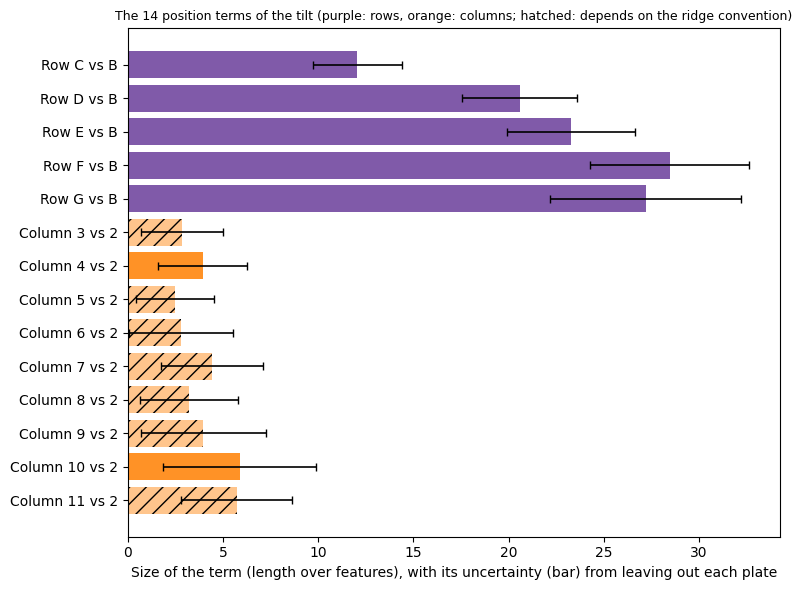

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(term_table))[::-1]
term_colors = ["#6a3d9a" if name.startswith("Row") else "#ff7f00" for name in term_table["term"]]
bars = ax.barh(y, term_table["size"], color=term_colors, alpha=0.85)
for bar, identified in zip(bars, term_table["identified"]):
    if not identified:
        bar.set_hatch("//")
        bar.set_alpha(0.45)
ax.errorbar(term_table["size"], y, xerr=term_table["uncertainty"], fmt="none", ecolor="black", capsize=3, lw=1.2)
ax.set_yticks(y)
ax.set_yticklabels(term_table["term"])
ax.set_xlabel("Size of the term (length over features), with its uncertainty (bar) from leaving out each plate")
ax.set_title("The 14 position terms of the tilt (purple: rows, orange: columns; hatched: depends on the ridge convention)", fontsize=9)
fig.tight_layout()
fig.savefig(figure_dir / "tilt_terms_and_uncertainty.png", dpi=150, bbox_inches="tight")
plt.show()